In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
# Load the dataset (Defining relative path for different OS)
DATA_DIR = Path('..') / 'data'

df = pd.read_csv(DATA_DIR / 'raw' / 'Telco-Customer-Churn.csv')

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

<Axes: xlabel='Churn', ylabel='count'>

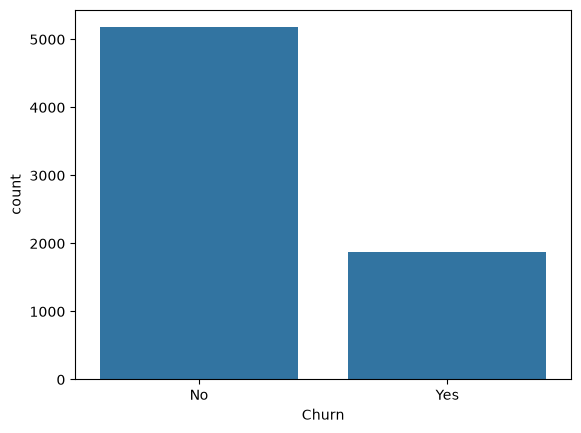

In [8]:
sns.countplot(x='Churn', data=df)

Approximately 26% of customers have churned, indicating a significant retention 
challenge for the telecom company.

In [9]:
# TotalCharges should be numeric but loaded as object dtype
# Scanning unique values to find what's causing it. (likely whitespace entries)
df['TotalCharges'].value_counts()

TotalCharges
20.2      11
          11
19.75      9
19.9       8
20.05      8
          ..
1990.5     1
7362.9     1
346.45     1
306.6      1
6844.5     1
Name: count, Length: 6531, dtype: int64

In [10]:
# Show which rows have a blank TotalCharges entry
# These turn out to be new customers with zero tenure who haven't been billed yet
df[df['TotalCharges'] == " "]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [11]:
# Coerce TotalCharges to numeric; whitespace strings become NaN and are handled in the next step

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors = 'coerce')

In [12]:
# Verify the conversion worked and check for any other missing values across all columns
df.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [13]:
# Drop the 11 rows where TotalCharges is NaN. All of them are zero-tenure new customers
# They make up < 0.2% of the dataset so removal is preferable to imputation here
df = df.dropna()

In [14]:
# Confirm we lost exactly the expected rows and nothing else
df.shape

(7032, 21)

The 11 affected rows all share tenure = 0, meaning these customers signed up but hadn't received their first bill yet. Imputing TotalCharges as 0 would have been equally valid, but since they represent a negligible share of the data and have no billing history to learn from, dropping them keeps the feature distributions clean.

In [15]:
# Churn rate by Contract type
# Month-to-month customers have no lock-in, so higher churn here is expected
pd.crosstab(df['Contract'], df['Churn'], normalize='index')

Churn,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887228,0.112772
Two year,0.971513,0.028487


Customers on month-to-month contracts exhibit significantly higher churn rates (42.7%) compared to customers with long-term contracts. This suggests that contract commitment plays a major role in customer retention.

In [16]:
# Churn rate by InternetService type

pd.crosstab(df['InternetService'], df['Churn'], normalize='index')

Churn,No,Yes
InternetService,,
DSL,0.810017,0.189983
Fiber optic,0.581072,0.418928
No,0.925658,0.074342


Fiber optic users churn at roughly 42% — comparable to month-to-month customers. One likely driver is price: fiber users tend to have higher monthly charges, and high-spend customers are often more willing to switch when a competitor offers a better deal. Worth cross-tabulating with contract type next. The model later shows this effect remains after controlling for MonthlyCharges

In [17]:
# Churn rate by PaymentMethod

pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index')

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),0.832685,0.167315
Credit card (automatic),0.847469,0.152531
Electronic check,0.547146,0.452854
Mailed check,0.807980,0.192020


Electronic check payers tend to churn the most (45.3%), possibly because auto-pay methods signal higher commitment to the service

<Axes: xlabel='Churn', ylabel='tenure'>

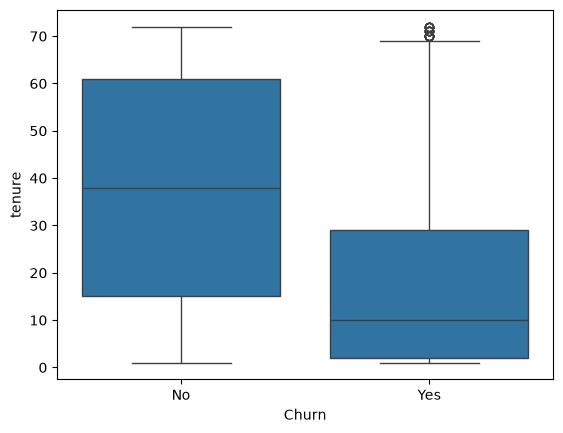

In [18]:
# Distribution of tenure split by churn status
# Churners tend to leave early, so we expect a lower median tenure on the Yes side

sns.boxplot(x='Churn', y='tenure', data=df)

<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

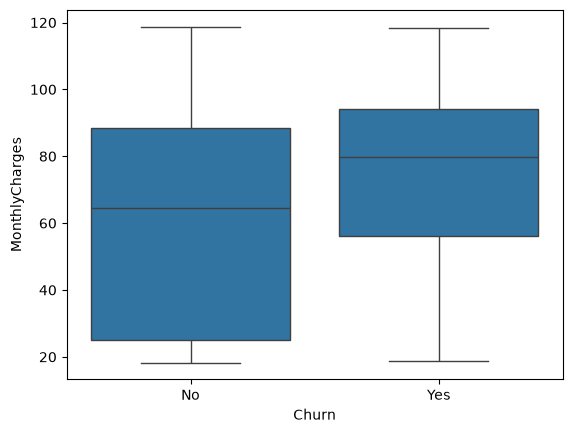

In [19]:
# Distribution of monthly charges split by churn status
# Higher charges may push customers to switch — worth checking the spread

sns.boxplot(x='Churn', y='MonthlyCharges', data=df)

In [20]:
# Mean tenure and monthly charges by churn label
# Quick sanity check to put numbers behind what the box plots showed

df.groupby('Churn')[['tenure','MonthlyCharges']].mean()

,tenure,MonthlyCharges
Churn,,
No,37.650010,61.307408
Yes,17.979133,74.441332


Churners average about 18 months of tenure versus 38 months for retained customers. The gap is large enough that tenure will likely be one of the most predictive features. Monthly charges are also noticeably higher for churners (~ \$74𝑣𝑠 
 \$61), reinforcing the price-sensitivity angle.

Breaking tenure into discrete buckets will make this gradient easier to communicate and also lets us check whether the risk is concentrated in a specific window or spreads across early months.

In [21]:
# Work on a copy to avoid modifying the original DataFrame in place
df = df.copy()

df.loc[:, 'tenure_group'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 24, 48, 60, 73],
    labels=['0-12', '12-24', '24-48', '48-60', '60-72'],
    include_lowest=True,
    right=True
)

In [22]:
# Churn rate within each tenure band.
pd.crosstab(df['tenure_group'], df['Churn'], normalize='index')

Churn,No,Yes
tenure_group,,
0-12,0.523218,0.476782
12-24,0.712891,0.287109
24-48,0.796110,0.203890
48-60,0.855769,0.144231
60-72,0.933902,0.066098


Churn is heavily front-loaded: customers in the 0–12 month band churn at ~48%, nearly double the overall dataset rate. The risk drops sharply after the first year and continues declining through each band. This pattern points to the first renewal window as the most critical intervention point: getting a customer past month 12 substantially improves long-term retention odds.

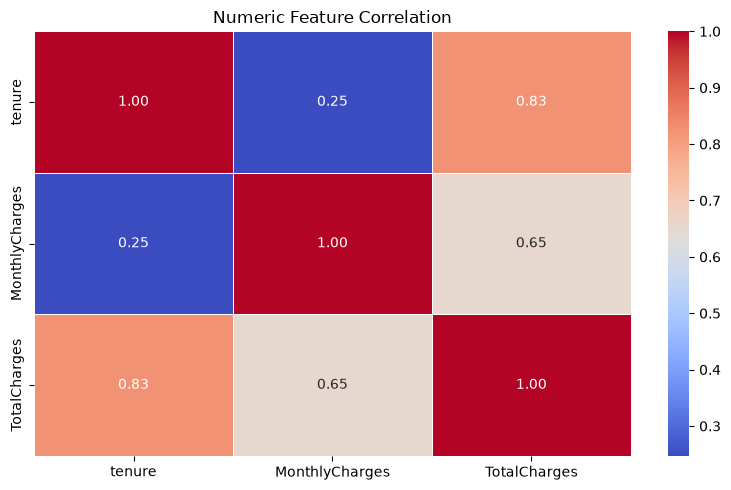

In [23]:
# Pearson correlation among the three numeric features.
# TotalCharges is roughly tenure × MonthlyCharges, so high collinearity is expected
plt.figure(figsize=(8, 5))
sns.heatmap(
    df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr(),
    annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5
)
plt.title('Numeric Feature Correlation')
plt.tight_layout()
plt.show()

TotalCharges correlates strongly with both tenure because it is effectively their product. It's kept in the feature set since tree-based models can still extract marginal signal from it, but it won't add much beyond what the other two already encode. In the modeling notebook a CLV proxy (tenure × MonthlyCharges) replaces it with a feature that carries clearer business interpretation.

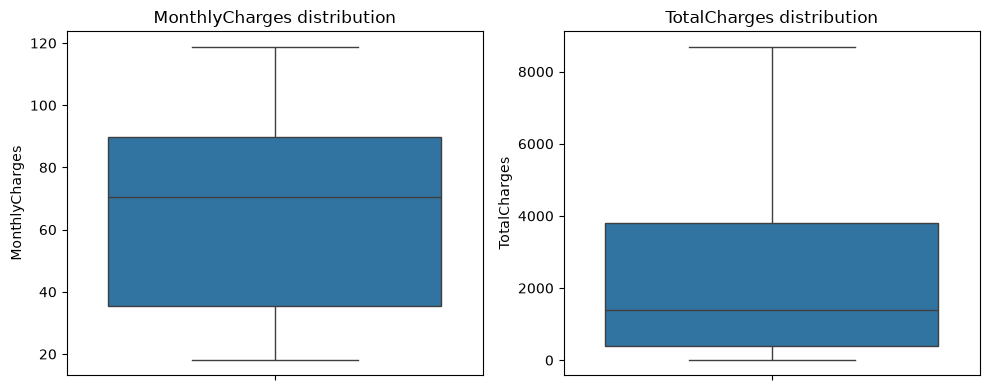

MonthlyCharges: 0 outliers detected
TotalCharges: 0 outliers detected


In [24]:
# Box plots and IQR-based outlier counts for the two charge columns
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df['MonthlyCharges'], ax=axes[0])
axes[0].set_title('MonthlyCharges distribution')
sns.boxplot(y=df['TotalCharges'], ax=axes[1])
axes[1].set_title('TotalCharges distribution')
plt.tight_layout()
plt.show()

# Quantify flagged rows using the standard 1.5 × IQR rule
for col in ['MonthlyCharges', 'TotalCharges']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)]
    print(f"{col}: {len(outliers)} outliers detected")

In [25]:
# Cross-tab Contract × InternetService to see whether the fiber churn risk
# holds across all contract types or is concentrated in month-to-month customers
interaction = pd.crosstab(
    [df['Contract'], df['InternetService']],
    df['Churn'],
    normalize='index'
).round(3)
print(interaction)

Churn                              No    Yes
Contract       InternetService              
Month-to-month DSL              0.678  0.322
               Fiber optic      0.454  0.546
               No               0.811  0.189
One year       DSL              0.907  0.093
               Fiber optic      0.807  0.193
               No               0.975  0.025
Two year       DSL              0.981  0.019
               Fiber optic      0.928  0.072
               No               0.992  0.008


In [26]:
# Persist the cleaned dataset for use in the modeling notebook.
df.to_csv(DATA_DIR / 'processed' / 'churn_clean.csv', index=False)